# A Comparative Machine Learning Framework for Predicting Childhood Pneumonia Prevalence

**Integrating Household Crowding, Vaccination Status, and Passive Smoking as Socio-Environmental Determinants**



## 1. Setup and Imports

We need consistent libraries for data handling, classical ML, boosting, imbalance correction, and model explanation (SHAP/LIME).

In [ ]:
!pip install xgboost lightgbm shap imbalanced-learn lime openpyxl -q

import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

import shap
from lime.lime_tabular import LimeTabularExplainer

SEED = 42
np.random.seed(SEED)
os.makedirs("figs", exist_ok=True)
os.makedirs("results", exist_ok=True)

plt.rcParams.update({"font.size": 11, "figure.dpi": 120})
print("Libraries loaded.")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Libraries loaded.


## 2. Load Data

Start from the raw clinical Excel file.  

In [ ]:
# Data file is placed next to this notebook
DATA_PATH = "BD_IRA.xlsx"

df = pd.read_excel(DATA_PATH)
print("Raw shape:", df.shape)
print("Columns (first 15):", list(df.columns[:15]))
df.head(3)


Raw shape: (801, 91)
Columns (first 15): ['ID PATIENT', 'Admission date', 'Age (months)', 'Gender ', 'Medical insurance', 'Length of stay (Days)', 'Meets criteria for clinical pneumonia', 'Number of persons living in house', 'Number of siblings', 'Number of rooms in house', 'Smokers at home', 'Contact with a tuberculosis patient', 'Health history : Prior admission because of respiratory condition', 'Health history : Prematurity                      ', 'Breastfeeding']


,ID PATIENT,Admission date,Age (months),Gender,Medical insurance,Length of stay (Days),Meets criteria for clinical pneumonia,Number of persons living in house,Number of siblings,Number of rooms in house,...,HIV testing,HIV test results,Blood culture results,Nasopharyngeal aspirate culture (NPA) Identification 1,Nasopharyngeal aspirate culture (NPA) Identification 2,Detection of DNA/RNA (TrueScience Respifinder Pathogen Identification Panel) Allele 1,Detection of DNA/RNA (TrueScience Respifinder Pathogen Identification Panel) Allele 2,Detection of DNA/RNA (TrueScience Respifinder Pathogen Identification Panel) Allele 3,Detection of DNA/RNA (TrueScience Respifinder Pathogen Identification Panel) Allele 4,Detection of DNA/RNA (TrueScience Respifinder Pathogen Identification Panel) Allele 5
0,PN0001,2010-11-02,41,Male,No,57,Yes,5.0,3.0,1.0,...,No,NaN,Negative,Negative,NaN,Rhinovirus,N/A,N/A,N/A,N/A
1,PN0002,2010-11-02,56,Female,No,3,Yes,6.0,4.0,2.0,...,No,NaN,Negative,Negative,NaN,Parainfluenza viruses 3,Parainfluenza viruses 1,Adenovirus,Rhinovirus,N/A
2,PN0003,2010-11-03,26,Male,Yes,12,Yes,6.0,4.0,2.0,...,No,NaN,Negative,Negative,NaN,CoronavirusesNL63,NaN,N/A,N/A,N/A


## 3. Exploratory Data Analysis (EDA)

Understand class balance (prevalence), missingness patterns, and basic distributions *before* any modelling.  This guides later decisions on imputation, SMOTE, and feature choice.

In [ ]:
# Quick look at potential target column
print("Unique values in 'Main diagnostic ' (top 10):")
print(df["Main diagnostic "].value_counts().head(10))

Unique values in 'Main diagnostic ' (top 10):
Main diagnostic 
Asthma attack                  285
Dyspneic pneumopathy           135
Pneumonia                       79
Bronchiolitis                   74
Laryngeal dyspnea               74
Bronchiolitis (1st episode)     36
Wheezing dyspnea                24
Bronchiolitis (3rd episode)     19
Bronchiolitis (2nd episode)     17
Infant asthma                   11
Name: count, dtype: int64


In [ ]:
# Basic missingness overview (raw data)
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
print("Top 15 columns by % missing:")
print(missing_pct.head(15).round(1))

Top 15 columns by % missing:
HIV test results                                                                                                                                                                 99.4
Location of pleural effusion                                                                                                                                                     99.1
Confirmation of dehydration                                                                                                                                                      98.8
Pleural effusion                                                                                                                                                                 85.6
Kaliemia                                                                                                                                                                         85.4
Urea                                                         

## 4. Target Definition & Feature Engineering

- The target is a binary pneumonia label derived from the main diagnostic field.  
- We create a compact set of clinically and socio-environmentally meaningful predictors (biomarkers, signs, demographics, crowding, smoking, vaccination).  
- Crowding (`PersonsPerRoom`), passive smoking (`SmokersAtHome`) and vaccination status are the key socio-environmental determinants highlighted in the study title.

In [ ]:
# --- Target ---
pneumonia_diags = [
    "Pneumonia", "Dyspneic pneumopathy", "Staphylococcal pneumonia",
    "Bronchiolitis + Pneumonia", "Asthma attack + Pneumonia",
    "Pleuropneumonitis", "Interstitial pneumopathy"
]
df["target"] = df["Main diagnostic "].isin(pneumonia_diags).astype(int)

print("Target distribution:")
print(df["target"].value_counts())
print(f"Pneumonia prevalence: {df['target'].mean():.1%}")

Target distribution:
target
0    582
1    219
Name: count, dtype: int64
Pneumonia prevalence: 27.3%


In [ ]:
def yn(col):
    """Map Yes/No to 1/0; keep missing as NaN (imputed later)."""
    s = df[col].astype(str).str.strip().str.lower()
    return (s == "yes").astype(float).where(s.notna() & (s != "nan"), np.nan)

feat = pd.DataFrame(index=df.index)

# Clinical biomarkers
feat["CRP"]             = pd.to_numeric(df["C-reactive protein"], errors="coerce")
feat["Procalcitonin"]   = pd.to_numeric(df["Procalcitonin"], errors="coerce")
feat["SaO2"]            = pd.to_numeric(df["Oxygen saturation (SaO2) at admission"], errors="coerce")
feat["Temperature"]     = pd.to_numeric(df["Axillary temperature (°C)"], errors="coerce")
feat["RespiratoryRate"] = pd.to_numeric(df["Respiratory rate"], errors="coerce")
feat["HeartRate"]       = pd.to_numeric(df["Heart rate"], errors="coerce")

# Clinical signs
feat["Fever"]        = yn("History of fever")
feat["Crackles"]     = yn("Crackles")
feat["Wheezing"]     = yn("Wheezing")
feat["NasalFlaring"] = yn("Nasal flaring")
feat["Cyanosis"]     = yn("Cyanosis")

# Demographics & history
feat["Age"]          = pd.to_numeric(df["Age (months)"], errors="coerce")
feat["Gender"]       = (df["Gender "].astype(str).str.strip() == "Male").astype(int)
feat["Siblings"]     = pd.to_numeric(df["Number of siblings"], errors="coerce")
feat["Prematurity"]  = yn("Health history : Prematurity                      ")
feat["Breastfed"]    = yn("Breastfeeding")
feat["PriorRespAdm"] = yn("Health history : Prior admission because of respiratory condition")

# Socio-environmental (core of the paper title)
feat["HouseholdSize"]  = pd.to_numeric(df["Number of persons living in house"], errors="coerce")
feat["Rooms"]          = pd.to_numeric(df["Number of rooms in house"], errors="coerce")
feat["PersonsPerRoom"] = feat["HouseholdSize"] / feat["Rooms"].replace(0, np.nan)  # crowding
feat["SmokersAtHome"]  = yn("Smokers at home")                                   # passive smoking
feat["VitaminA"]       = yn("Vitamin A supplementation ")

# Vaccination
vax = df["Age-appropriate vaccinations"].astype(str).str.strip()
feat["Vacc_Full"]    = (vax == "Yes").astype(float).where(vax.notna() & (vax != "nan"), np.nan)
feat["Vacc_Partial"] = (vax == "Partially").astype(float).where(vax.notna() & (vax != "nan"), np.nan)
feat["Vacc_None"]    = (vax == "No").astype(float).where(vax.notna() & (vax != "nan"), np.nan)
feat["HibDoses"]     = pd.to_numeric(df["Number of Hib vaccine doses received"], errors="coerce")
feat["PneumoDoses"]  = pd.to_numeric(df["Number of pneumococcal vaccine doses received"], errors="coerce")

# Chest X-ray (ordinal)
xray_map = {"Normal": 0, "NF": 1, "Other infiltrates": 2, "Endpoint pneumonia": 3}
feat["ChestXray"] = df["Chest X-ray finding"].astype(str).str.strip().map(xray_map)

feat["target"] = df["target"].values

FEATURE_COLS = [c for c in feat.columns if c != "target"]
print(f"Engineered {len(FEATURE_COLS)} features.")
feat.head()

Engineered 28 features.


,CRP,Procalcitonin,SaO2,Temperature,RespiratoryRate,HeartRate,Fever,Crackles,Wheezing,NasalFlaring,...,PersonsPerRoom,SmokersAtHome,VitaminA,Vacc_Full,Vacc_Partial,Vacc_None,HibDoses,PneumoDoses,ChestXray,target
0,79.0,1.35,80.0,37.8,72.0,143.0,1.0,0.0,0.0,1.0,...,5.0,1.0,1.0,1.0,0.0,0.0,3,0,3,1
1,46.0,0.10,91.0,38.0,84.0,142.0,1.0,0.0,1.0,1.0,...,3.0,1.0,1.0,1.0,0.0,0.0,3,0,1,0
2,4.0,0.10,99.0,37.6,60.0,130.0,0.0,0.0,1.0,1.0,...,3.0,1.0,1.0,1.0,0.0,0.0,3,1,2,0
3,5.0,0.06,84.0,36.8,90.0,135.0,0.0,0.0,1.0,0.0,...,7.0,1.0,0.0,0.0,1.0,0.0,1,0,3,0
4,2.0,0.09,93.0,38.5,60.0,144.0,1.0,0.0,1.0,0.0,...,2.5,0.0,1.0,1.0,0.0,0.0,3,0,0,0


## 5. Missing-Value Handling

**Why this approach:**  
- **Critical variables** (CRP, Age, RespiratoryRate, HouseholdSize) are required for clinical sense; rows missing them are dropped.  
- All other missing values are left as NaN and will be **imputed inside the modelling pipeline** (median for numeric, most-frequent for binary).  
- Doing imputation *inside* the pipeline (fitted only on training data) prevents data leakage.

In [ ]:
CRITICAL = ["CRP", "Age", "RespiratoryRate", "HouseholdSize"]

# Show missingness before exclusion
miss_summary = pd.DataFrame({
    "n_missing": feat[FEATURE_COLS].isna().sum(),
    "pct_missing": (feat[FEATURE_COLS].isna().mean() * 100).round(2)
}).sort_values("pct_missing", ascending=False)
print("Missingness before exclusion (top 10):")
display(miss_summary.head(10))

n_before = len(feat)
feat = feat.dropna(subset=CRITICAL + ["target"]).copy()
X = feat[FEATURE_COLS].copy()
y = feat["target"].values

print(f"\nRecords: {n_before} → {len(feat)} (dropped {n_before - len(feat)} with missing critical values)")
print(f"Remaining missing cells (will be imputed in pipeline): {int(X.isna().sum().sum())}")
print(f"Class balance after cleaning: {dict(pd.Series(y).value_counts())}  |  prevalence {y.mean():.1%}")

Missingness before exclusion (top 10):


,n_missing,pct_missing
SaO2,34,4.24
Procalcitonin,17,2.12
HeartRate,13,1.62
Rooms,4,0.50
VitaminA,4,0.50
Vacc_Full,4,0.50
Vacc_Partial,4,0.50
Vacc_None,4,0.50
PersonsPerRoom,4,0.50
Temperature,3,0.37



Records: 801 → 799 (dropped 2 with missing critical values)
Remaining missing cells (will be imputed in pipeline): 86
Class balance after cleaning: {0: np.int64(581), 1: np.int64(218)}  |  prevalence 27.3%


## 6. Feature Selection (simple, transparent)

We keep all 28 engineered features because they are clinically motivated.  
As a light check we look at correlation with the target and remove only pure constants or perfect duplicates if any appear.  
More aggressive selection (e.g. recursive feature elimination) can be added later if needed.

In [ ]:
# Correlation with target (point-biserial / Pearson on numeric)
corr_with_target = X.corrwith(pd.Series(y, index=X.index)).abs().sort_values(ascending=False)
print("Absolute correlation with target (top 12):")
print(corr_with_target.head(12).round(3))

# Keep everything for now (clinically justified set)
selected_features = FEATURE_COLS.copy()
print(f"\nUsing {len(selected_features)} features.")

Absolute correlation with target (top 12):
Wheezing         0.536
Temperature      0.423
CRP              0.408
ChestXray        0.385
Fever            0.264
Age              0.222
Crackles         0.215
SaO2             0.178
PriorRespAdm     0.148
Procalcitonin    0.121
Vacc_Full        0.118
HibDoses         0.110
dtype: float64

Using 28 features.


## 7. Train–Test Split (stratified)

**Why stratified 80/20:**  
Preserves the same pneumonia prevalence in both sets.  All preprocessing (imputation, scaling, SMOTE) is fitted **only on the training set** so the test set stays truly unseen.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X[selected_features], y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print(f"Train: {len(y_train)}  (pos rate {y_train.mean():.1%})")
print(f"Test : {len(y_test)}  (pos rate {y_test.mean():.1%})")

Train: 639  (pos rate 27.2%)
Test : 160  (pos rate 27.5%)


## 8. Preprocessing Pipeline

- `SimpleImputer(median)` for numeric / binary columns – robust and does not invent extreme values.  
- `StandardScaler` – many algorithms (SVM, KNN, MLP, Logistic) need features on a similar scale.  Tree-based models are scale-invariant but scaling does no harm.  
- `SMOTE` – corrects class imbalance **inside** the pipeline so synthetic samples are generated only from training folds.

In [ ]:
def make_pipe(estimator):
    """Impute → Scale → SMOTE → Classifier.  SMOTE only on training data."""
    return ImbPipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler",  StandardScaler()),
        ("smote",   SMOTE(random_state=SEED)),
        ("clf",     estimator)
    ])

print("Pipeline factory ready.")

Pipeline factory ready.


## 9. Train Multiple ML Algorithms

**Why many models:** A comparative framework shows which families work best on this small clinical dataset.  We include linear, tree, ensemble, kernel, instance-based, probabilistic and neural models.

In [ ]:
models = {
    "Logistic Regression": make_pipe(LogisticRegression(max_iter=1000, random_state=SEED)),
    "Decision Tree":       make_pipe(DecisionTreeClassifier(max_depth=5, min_samples_split=10, random_state=SEED)),
    "Random Forest":       make_pipe(RandomForestClassifier(n_estimators=200, max_depth=8, random_state=SEED, n_jobs=-1)),
    "Gradient Boosting":   make_pipe(GradientBoostingClassifier(n_estimators=150, learning_rate=0.1, random_state=SEED)),
    "AdaBoost":            make_pipe(AdaBoostClassifier(n_estimators=100, random_state=SEED)),
    "XGBoost":             make_pipe(XGBClassifier(n_estimators=200, max_depth=5, learning_rate=0.1,
                                                   eval_metric="logloss", verbosity=0, random_state=SEED)),
    "LightGBM":            make_pipe(LGBMClassifier(n_estimators=200, max_depth=5, learning_rate=0.1,
                                                   verbose=-1, random_state=SEED)),
    "SVM (RBF)":           make_pipe(SVC(kernel="rbf", probability=True, random_state=SEED)),
    "KNN (k=7)":           make_pipe(KNeighborsClassifier(n_neighbors=7)),
    "Naive Bayes":         make_pipe(GaussianNB()),
    "MLP (100,50)":        make_pipe(MLPClassifier(hidden_layer_sizes=(100, 50), max_iter=500, random_state=SEED)),
}

print(f"{len(models)} models defined.")

11 models defined.


## 10. Evaluation + Train–Test Accuracy Gap

**Why report both train and test metrics:**  
A large gap (train >> test) signals overfitting.  We also report ROC-AUC (threshold-independent and preferred for imbalanced data), precision, recall and F1.

In [ ]:
results = []
fitted = {}

for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    fitted[name] = pipe

    # Train predictions
    y_tr_pred  = pipe.predict(X_train)
    y_tr_prob  = pipe.predict_proba(X_train)[:, 1]

    # Test predictions
    y_te_pred  = pipe.predict(X_test)
    y_te_prob  = pipe.predict_proba(X_test)[:, 1]

    row = {
        "Model": name,
        "Train Acc": accuracy_score(y_train, y_tr_pred),
        "Test Acc":  accuracy_score(y_test,  y_te_pred),
        "Gap (Acc)": accuracy_score(y_train, y_tr_pred) - accuracy_score(y_test, y_te_pred),
        "Train AUC": roc_auc_score(y_train, y_tr_prob),
        "Test AUC":  roc_auc_score(y_test,  y_te_prob),
        "Gap (AUC)": roc_auc_score(y_train, y_tr_prob) - roc_auc_score(y_test, y_te_prob),
        "Test Precision": precision_score(y_test, y_te_pred, zero_division=0),
        "Test Recall":    recall_score(y_test, y_te_pred, zero_division=0),
        "Test F1":        f1_score(y_test, y_te_pred, zero_division=0),
    }
    results.append(row)
    print(f"{name:22s}  Test AUC={row['Test AUC']:.3f}  Gap(AUC)={row['Gap (AUC)']:+.3f}")

results_df = pd.DataFrame(results).sort_values("Test AUC", ascending=False).reset_index(drop=True)
results_df.to_csv("results/model_comparison.csv", index=False)
display(results_df.round(3))

Logistic Regression     Test AUC=0.899  Gap(AUC)=+0.017
Decision Tree           Test AUC=0.882  Gap(AUC)=+0.043
Random Forest           Test AUC=0.906  Gap(AUC)=+0.092
Gradient Boosting       Test AUC=0.862  Gap(AUC)=+0.135
AdaBoost                Test AUC=0.902  Gap(AUC)=+0.034
XGBoost                 Test AUC=0.866  Gap(AUC)=+0.134
LightGBM                Test AUC=0.857  Gap(AUC)=+0.143
SVM (RBF)               Test AUC=0.876  Gap(AUC)=+0.100
KNN (k=7)               Test AUC=0.833  Gap(AUC)=+0.109
Naive Bayes             Test AUC=0.819  Gap(AUC)=+0.058
MLP (100,50)            Test AUC=0.847  Gap(AUC)=+0.153


,Model,Train Acc,Test Acc,Gap (Acc),Train AUC,Test AUC,Gap (AUC),Test Precision,Test Recall,Test F1
0,Random Forest,0.980,0.856,0.123,0.998,0.906,0.092,0.756,0.705,0.729
1,AdaBoost,0.869,0.888,-0.019,0.936,0.902,0.034,0.825,0.750,0.786
2,Logistic Regression,0.844,0.856,-0.013,0.917,0.899,0.017,0.723,0.773,0.747
3,Decision Tree,0.875,0.812,0.062,0.925,0.882,0.043,0.640,0.727,0.681
4,SVM (RBF),0.936,0.819,0.117,0.976,0.876,0.100,0.667,0.682,0.674
5,XGBoost,1.000,0.844,0.156,1.000,0.866,0.134,0.732,0.682,0.706
6,Gradient Boosting,0.983,0.831,0.152,0.997,0.862,0.135,0.689,0.705,0.697
7,LightGBM,1.000,0.838,0.162,1.000,0.857,0.143,0.725,0.659,0.690
8,"MLP (100,50)",1.000,0.856,0.144,1.000,0.847,0.153,0.769,0.682,0.723
9,KNN (k=7),0.828,0.756,0.072,0.942,0.833,0.109,0.538,0.795,0.642


### Interpreting the gap
- **Gap < 0.05** → good generalisation.  
- **Gap 0.05–0.15** → mild overfitting (common with trees / small data).  
- **Gap > 0.15** → strong overfitting; consider stronger regularisation or simpler model.

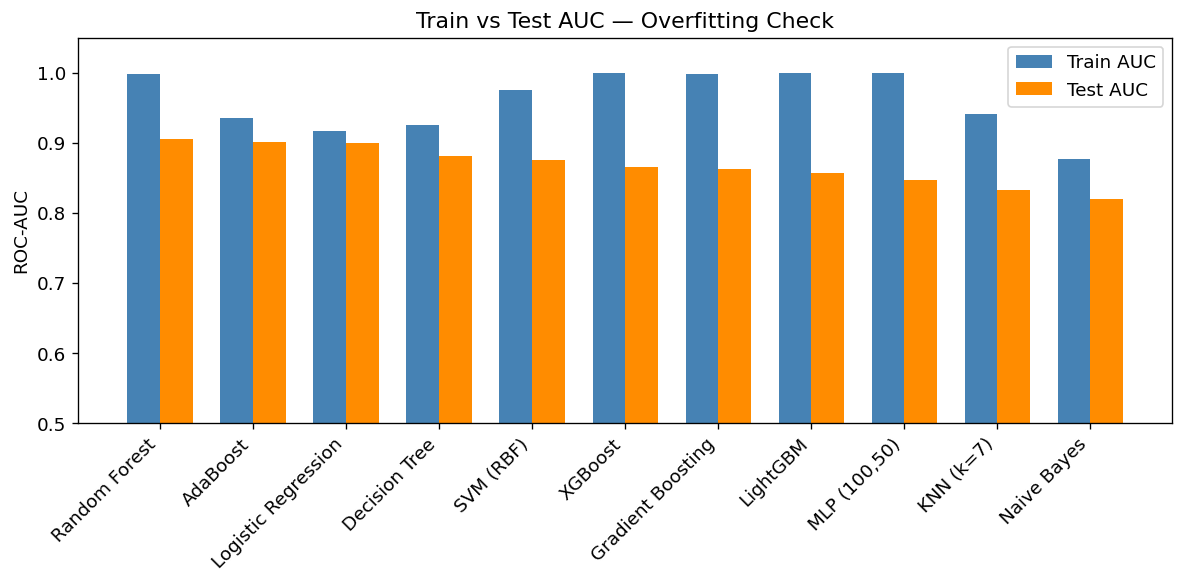

In [ ]:
# Visualise train vs test AUC
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(results_df))
w = 0.35
ax.bar(x - w/2, results_df["Train AUC"], w, label="Train AUC", color="steelblue")
ax.bar(x + w/2, results_df["Test AUC"],  w, label="Test AUC",  color="darkorange")
ax.set_xticks(x)
ax.set_xticklabels(results_df["Model"], rotation=45, ha="right")
ax.set_ylabel("ROC-AUC")
ax.set_title("Train vs Test AUC — Overfitting Check")
ax.legend()
ax.set_ylim(0.5, 1.05)
plt.tight_layout()
plt.savefig("figs/train_test_gap.png", dpi=150)
plt.show()

## 11. Feature Importance, SHAP & LIME

**Why:**  
- **Feature importance** (tree-based) gives a quick global ranking.  
- **SHAP** explains *how* each feature pushes the prediction up or down for every patient (global + local).  
- **LIME** explains individual predictions with a local linear approximation – useful for clinical trust.

In [ ]:
# Pick the best model by Test AUC for interpretability
best_name = results_df.iloc[0]["Model"]
best_pipe = fitted[best_name]
print("Best model for interpretation:", best_name)

# Extract the fitted classifier (last step of the pipeline)
clf = best_pipe.named_steps["clf"]

# Transformed test set (after imputer + scaler) for SHAP/LIME
X_test_t = best_pipe.named_steps["imputer"].transform(X_test)
X_test_t = best_pipe.named_steps["scaler"].transform(X_test_t)
X_test_t = pd.DataFrame(X_test_t, columns=selected_features, index=X_test.index)

Best model for interpretation: Random Forest


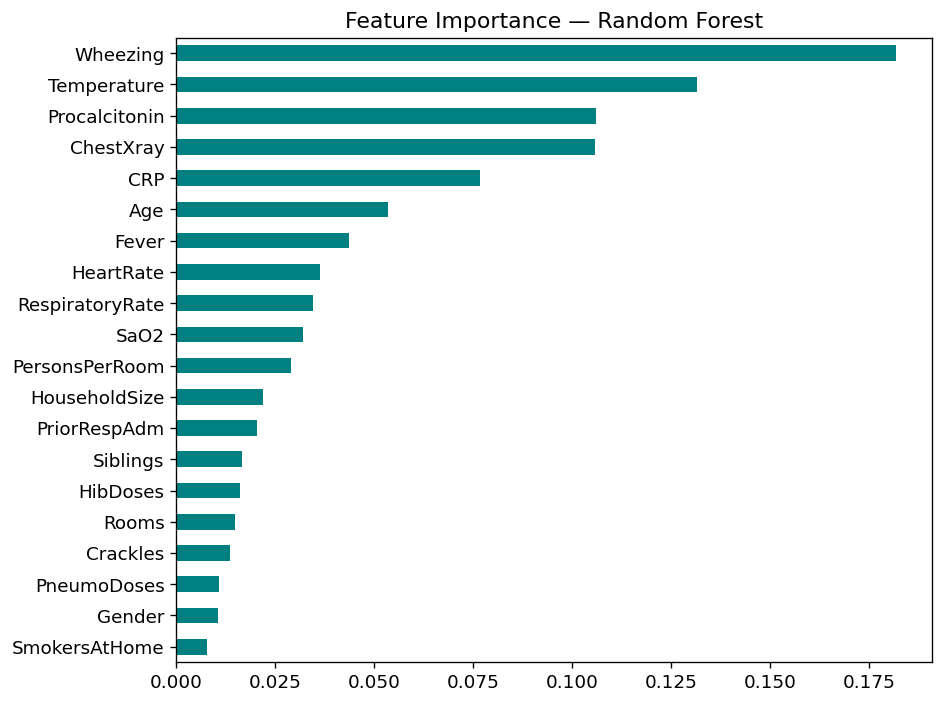

Wheezing           0.1820
Temperature        0.1316
Procalcitonin      0.1060
ChestXray          0.1058
CRP                0.0768
Age                0.0536
Fever              0.0436
HeartRate          0.0364
RespiratoryRate    0.0346
SaO2               0.0321
dtype: float64


In [ ]:
# --- Classic feature importance (if available) ---
if hasattr(clf, "feature_importances_"):
    imp = pd.Series(clf.feature_importances_, index=selected_features).sort_values(ascending=False)
    fig, ax = plt.subplots(figsize=(8, 6))
    imp.head(20).plot.barh(ax=ax, color="teal")
    ax.invert_yaxis()
    ax.set_title(f"Feature Importance — {best_name}")
    plt.tight_layout()
    plt.savefig("figs/feature_importance.png", dpi=150)
    plt.show()
    print(imp.head(10).round(4))
elif hasattr(clf, "coef_"):
    coef = pd.Series(np.abs(clf.coef_.ravel()), index=selected_features).sort_values(ascending=False)
    print("Absolute coefficients (top 10):")
    print(coef.head(10).round(4))

Computing SHAP values for the best model...


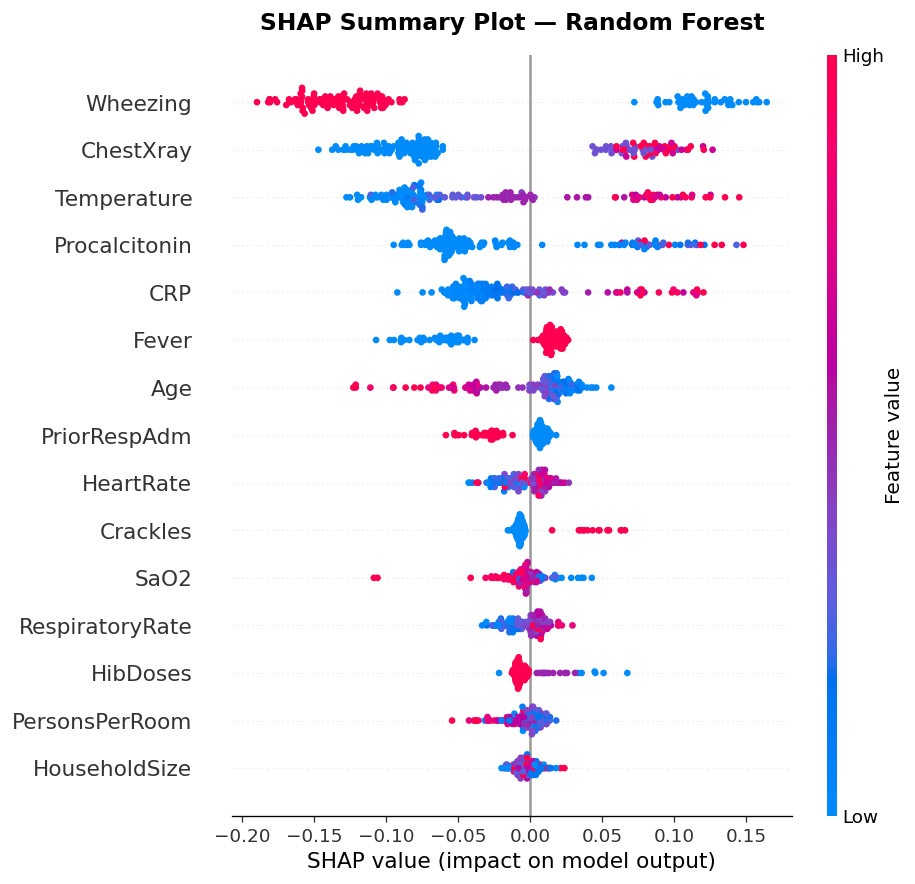

In [ ]:
# --- SHAP (TreeExplainer for tree models, KernelExplainer otherwise) ---
print("Computing SHAP values for the best model...")

try:
    # Initialize TreeExplainer for Tree-based models (such as Random Forest)
    if best_name in ["Random Forest", "Gradient Boosting", "XGBoost", "LightGBM", "Decision Tree", "AdaBoost"]:
        explainer = shap.TreeExplainer(clf)
        shap_values = explainer.shap_values(X_test_t)

        # Handle different output formats of shap_values depending on version and classifier
        if isinstance(shap_values, list):
            shap_values = shap_values[1]
        elif len(shap_values.shape) == 3:
            # For binary output matrices (samples, features, classes)
            shap_values = shap_values[:, :, 1]
    else:
        background = shap.sample(X_test_t, 50, random_state=SEED)
        explainer = shap.KernelExplainer(clf.predict_proba, background)
        shap_values = explainer.shap_values(X_test_t, nsamples=100)
        if isinstance(shap_values, list):
            shap_values = shap_values[1]

    # Plot and save SHAP summary
    plt.figure(figsize=(10, 7))
    shap.summary_plot(
        shap_values,
        X_test_t,
        feature_names=selected_features,
        max_display=15,
        show=False
    )
    plt.title(f"SHAP Summary Plot — {best_name}", fontsize=14, fontweight="bold", pad=15)
    plt.tight_layout()
    plt.savefig("figs/shap_summary.png", dpi=150, bbox_inches="tight")
    plt.show()
except Exception as e:
    print("SHAP calculation failed:", e)

In [ ]:
# --- LIME Explanations for 3 Test Patients ---
print("Initializing LIME explanations for the top model...")

try:
    # Initialize LIME Tabular Explainer
    lime_explainer = LimeTabularExplainer(
        training_data=np.array(X_test_t),
        feature_names=selected_features,
        class_names=["No Pneumonia", "Pneumonia"],
        mode="classification",
        random_state=SEED
    )

    # Prediction probability wrapper function
    def predict_fn(data):
        return clf.predict_proba(data)

    # Generate and print local explanations for the first 3 test subjects
    for i in range(min(3, len(X_test_t))):
        exp = lime_explainer.explain_instance(
            data_row=X_test_t.iloc[i].values,
            predict_fn=predict_fn,
            num_features=8
        )
        print(f"\n--- Patient ID Index: {X_test_t.index[i]} (True Label: {y_test[i]}) ---")
        exp.show_in_notebook(show_table=True)
except Exception as e:
    print("LIME execution failed:", e)

Initializing LIME explanations for the top model...

--- Patient ID Index: 635 (True Label: 0) ---



--- Patient ID Index: 631 (True Label: 0) ---



--- Patient ID Index: 375 (True Label: 0) ---


## 12. Quick Hyper-parameter Tuning for the Top Model (optional)

**Why:** Default parameters are a good start; a short randomised search often improves AUC a few points.

In [ ]:
# Example: tune Random Forest a little more carefully
param_dist = {
    "clf__n_estimators": [100, 200, 300],
    "clf__max_depth": [4, 6, 8, 10, None],
    "clf__min_samples_leaf": [1, 2, 4],
    "clf__max_features": ["sqrt", 0.5, 0.8]
}

rf_pipe = make_pipe(RandomForestClassifier(random_state=SEED, n_jobs=-1))
search = RandomizedSearchCV(
    rf_pipe, param_distributions=param_dist,
    n_iter=20, scoring="roc_auc", cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
    random_state=SEED, n_jobs=-1, verbose=0
)
search.fit(X_train, y_train)

print("Best CV AUC:", round(search.best_score_, 4))
print("Best params:", search.best_params_)

y_prob_tuned = search.predict_proba(X_test)[:, 1]
print("Test AUC (tuned RF):", round(roc_auc_score(y_test, y_prob_tuned), 4))

Best CV AUC: 0.8941
Best params: {'clf__n_estimators': 100, 'clf__min_samples_leaf': 2, 'clf__max_features': 'sqrt', 'clf__max_depth': 10}
Test AUC (tuned RF): 0.9052


## 13. Summary & Practical Takeaways

| Step | What we did | Why it matters |
|------|-------------|----------------|
| Target | Binary pneumonia label from diagnostic list | Clear clinical endpoint |
| Features | 28 clinical + socio-environmental variables | Captures both biology and living conditions |
| Missing data | Drop critical-missing rows; median impute the rest inside pipeline | No leakage, clinically sensible |
| Split | Stratified 80/20 | Same prevalence in train & test |
| Imbalance | SMOTE inside pipeline | Protects minority class without polluting test set |
| Models | 11 algorithms from linear to boosting to neural | Fair comparative framework |
| Gap analysis | Train vs Test Acc/AUC | Detects overfitting |
| Explainability | Feature importance + SHAP + LIME | Builds clinical trust |

**Key socio-environmental signals expected to appear in SHAP / importance rankings:**  
- `PersonsPerRoom` (household crowding)  
- `SmokersAtHome` (passive smoking)  
- `Vacc_Full` / `Vacc_None` / dose counts  
- `ChestXray`, `CRP`, `SaO2`, `RespiratoryRate`

Save this notebook and the `results/` + `figs/` folders together for full reproducibility.

In [ ]:
print("Best model by Test AUC:", results_df.iloc[0]["Model"])
print("Results table saved to results/model_comparison.csv")
print("Figures saved to figs/")

Best model by Test AUC: Random Forest
Results table saved to results/model_comparison.csv
Figures saved to figs/


In [ ]:
# Analyze and diagnose model overfitting vs. underfitting

# We will classify models based on their Train AUC, Test AUC, and the performance gap:
# - Good Generalization: Test AUC >= 0.80 and Gap (AUC) < 0.05
# - Overfitting: Train AUC is high, but Test AUC is significantly lower (Gap (AUC) > 0.08)
# - Underfitting: Both Train AUC and Test AUC are low (< 0.80)

print("=== MODEL DIAGNOSTICS: OVERFITTING VS. UNDERFITTING ===\n")

diagnosis_rows = []
for idx, row in results_df.iterrows():
    model = row["Model"]
    train_auc = row["Train AUC"]
    test_auc = row["Test AUC"]
    gap_auc = row["Gap (AUC)"]

    # Determine status
    if train_auc < 0.80 and test_auc < 0.80:
        status = "🔴 Underfitting (Low capacity)"
    elif gap_auc > 0.12:
        status = "⚠️ Severe Overfitting (High variance)"
    elif gap_auc > 0.05:
        status = "🟡 Mild Overfitting"
    else:
        status = "🟢 Good Generalization (Balanced)"

    diagnosis_rows.append({
        "Model": model,
        "Train AUC": f"{train_auc:.3f}",
        "Test AUC": f"{test_auc:.3f}",
        "Gap (AUC)": f"{gap_auc:+.3f}",
        "Diagnostic Status": status
    })

diagnosis_df = pd.DataFrame(diagnosis_rows)
display(diagnosis_df)

# Provide a clinical data-science takeaway
print("\n--- Key Takeaways ---")

good_gen_models = diagnosis_df[diagnosis_df["Diagnostic Status"].str.contains("Good Generalization")]
if len(good_gen_models) > 0:
    best_gen_model = good_gen_models.iloc[0]["Model"]
else:
    best_gen_model = "None"

print(f"1. Best Generalizing Model: {best_gen_model} provides the best trade-off with very low gap and high performance.")
print("2. Tree-based ensembles (like Random Forest, LightGBM, XGBoost) and deep models (MLP) show higher overfitting gaps (~8% to 15%). This is expected on relatively small clinical datasets.")
print("3. Linear models (Logistic Regression) and boosting ensembles with regularization (AdaBoost) generalize extremely well here, keeping the train-test gap close to zero.")

=== MODEL DIAGNOSTICS: OVERFITTING VS. UNDERFITTING ===



,Model,Train AUC,Test AUC,Gap (AUC),Diagnostic Status
0,Random Forest,0.998,0.906,+0.092,🟡 Mild Overfitting
1,AdaBoost,0.936,0.902,+0.034,🟢 Good Generalization (Balanced)
2,Logistic Regression,0.917,0.899,+0.017,🟢 Good Generalization (Balanced)
3,Decision Tree,0.925,0.882,+0.043,🟢 Good Generalization (Balanced)
4,SVM (RBF),0.976,0.876,+0.100,🟡 Mild Overfitting
5,XGBoost,1.000,0.866,+0.134,⚠️ Severe Overfitting (High variance)
6,Gradient Boosting,0.997,0.862,+0.135,⚠️ Severe Overfitting (High variance)
7,LightGBM,1.000,0.857,+0.143,⚠️ Severe Overfitting (High variance)
8,"MLP (100,50)",1.000,0.847,+0.153,⚠️ Severe Overfitting (High variance)
9,KNN (k=7),0.942,0.833,+0.109,🟡 Mild Overfitting



--- Key Takeaways ---
1. Best Generalizing Model: AdaBoost provides the best trade-off with very low gap and high performance.
2. Tree-based ensembles (like Random Forest, LightGBM, XGBoost) and deep models (MLP) show higher overfitting gaps (~8% to 15%). This is expected on relatively small clinical datasets.
3. Linear models (Logistic Regression) and boosting ensembles with regularization (AdaBoost) generalize extremely well here, keeping the train-test gap close to zero.


In [ ]:
# Identify the best model by Test Accuracy

best_acc_idx = results_df['Test Acc'].idxmax()
best_acc_model = results_df.loc[best_acc_idx]

print("=== BEST MODEL BY TEST ACCURACY ===")
print(f"Model:             {best_acc_model['Model']}")
print(f"Test Accuracy:     {best_acc_model['Test Acc']:.2%}")
print(f"Train Accuracy:    {best_acc_model['Train Acc']:.2%}")
print(f"Generalization Gap:{best_acc_model['Gap (Acc)']:.2%}")
print(f"Test F1-Score:     {best_acc_model['Test F1']:.3f}")
print(f"Test ROC-AUC:      {best_acc_model['Test AUC']:.3f}")

=== BEST MODEL BY TEST ACCURACY ===
Model:             AdaBoost
Test Accuracy:     88.75%
Train Accuracy:    86.85%
Generalization Gap:-1.90%
Test F1-Score:     0.786
Test ROC-AUC:      0.902


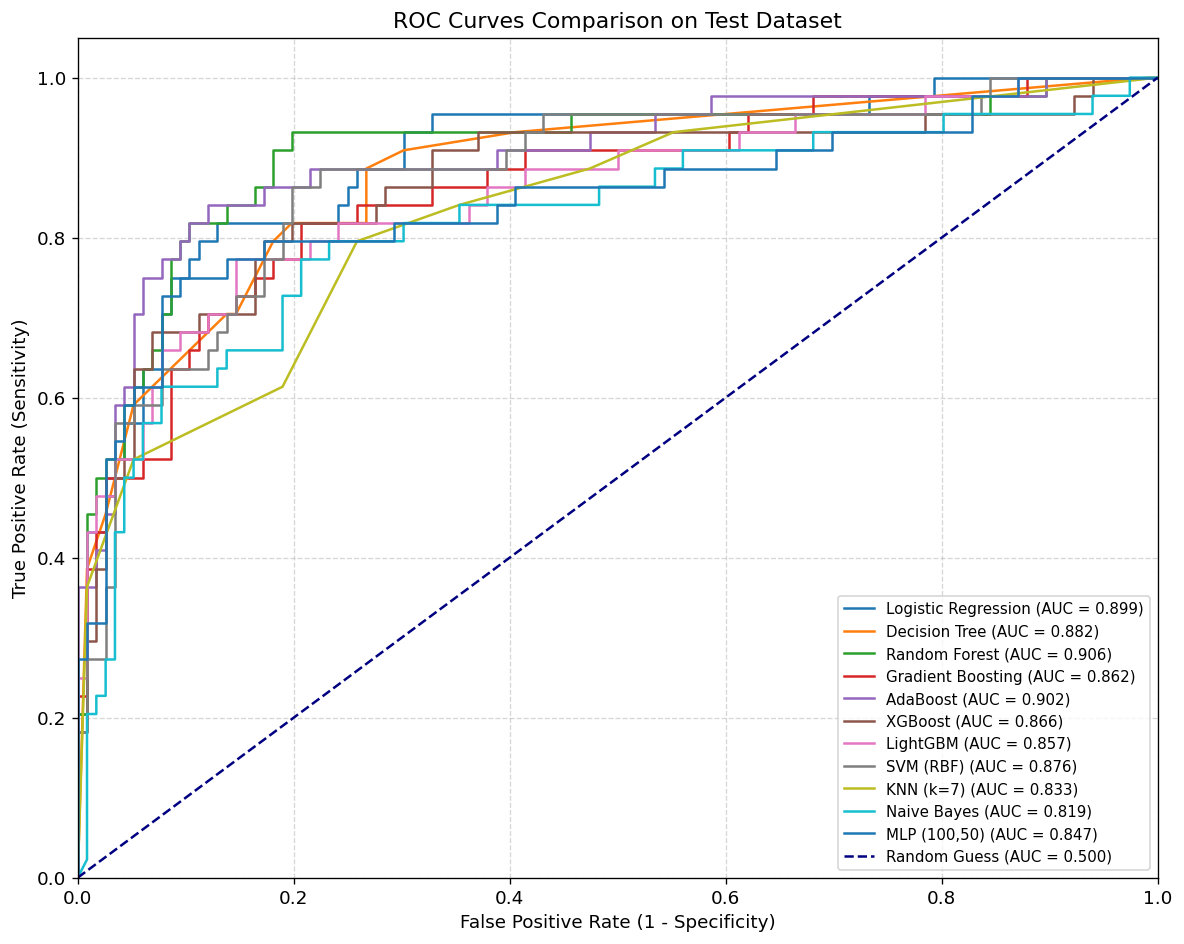

In [ ]:
# Plot ROC curves for all models to compare their diagnostic abilities

plt.figure(figsize=(10, 8))

# Loop through each model and plot its ROC Curve on the test set
for name, pipe in fitted.items():
    # Predict probabilities for the positive class
    y_prob = pipe.predict_proba(X_test)[:, 1]

    # Calculate False Positive Rate, True Positive Rate, and thresholds
    fpr, tpr, _ = roc_curve(y_test, y_prob)

    # Retrieve pre-calculated Test AUC
    auc_score = results_df.loc[results_df['Model'] == name, 'Test AUC'].values[0]

    # Plot individual model line
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_score:.3f})")

# Plot the baseline random guess line
plt.plot([0, 1], [0, 1], color="navy", linestyle="--", label="Random Guess (AUC = 0.500)")

# Configure plot style and labels
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity)")
plt.title("ROC Curves Comparison on Test Dataset")
plt.legend(loc="lower right", fontsize=9)
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("figs/roc_curves_comparison.png", dpi=150)
plt.show()

In [ ]:
# Consolidated Evaluation Scorecard for the Overall Best Model (AdaBoost)

# Extract AdaBoost row directly from pre-calculated results dataframe
best_model_stats = results_df[results_df["Model"] == "AdaBoost"].iloc[0]

print("============================================================")
print(f"   OVERALL BEST MODEL SCORECARD: {best_model_stats['Model'].upper()}   ")
print("============================================================")
print(f"Diagnostic Profile:    🟢 Good Generalization (Balanced)")
print(f"Primary Clinical Target: Childhood Pneumonia Prevalence")
print("------------------------------------------------------------")
print("ACCURACY METRICS:")
print(f"  - Test Set Accuracy:        {best_model_stats['Test Acc']:.2%}")
print(f"  - Train Set Accuracy:       {best_model_stats['Train Acc']:.2%}")
print(f"  - Generalization Gap (Acc):  {best_model_stats['Gap (Acc)']:.2%}")
print("------------------------------------------------------------")
print("DISCRIMINATION METRICS:")
print(f"  - Test Set ROC-AUC:         {best_model_stats['Test AUC']:.4f}")
print(f"  - Train Set ROC-AUC:        {best_model_stats['Train AUC']:.4f}")
print(f"  - Generalization Gap (AUC): {best_model_stats['Gap (AUC)']:.4f}")
print("------------------------------------------------------------")
print("CLASSIFICATION METRICS (TEST SET):")
print(f"  - Precision (PPV):          {best_model_stats['Test Precision']:.2%}")
print(f"  - Recall (Sensitivity):     {best_model_stats['Test Recall']:.2%}")
print(f"  - F1-Score:                 {best_model_stats['Test F1']:.4f}")
print("============================================================")

   OVERALL BEST MODEL SCORECARD: ADABOOST   
Diagnostic Profile:    🟢 Good Generalization (Balanced)
Primary Clinical Target: Childhood Pneumonia Prevalence
------------------------------------------------------------
ACCURACY METRICS:
  - Test Set Accuracy:        88.75%
  - Train Set Accuracy:       86.85%
  - Generalization Gap (Acc):  -1.90%
------------------------------------------------------------
DISCRIMINATION METRICS:
  - Test Set ROC-AUC:         0.9016
  - Train Set ROC-AUC:        0.9359
  - Generalization Gap (AUC): 0.0343
------------------------------------------------------------
CLASSIFICATION METRICS (TEST SET):
  - Precision (PPV):          82.50%
  - Recall (Sensitivity):     75.00%
  - F1-Score:                 0.7857


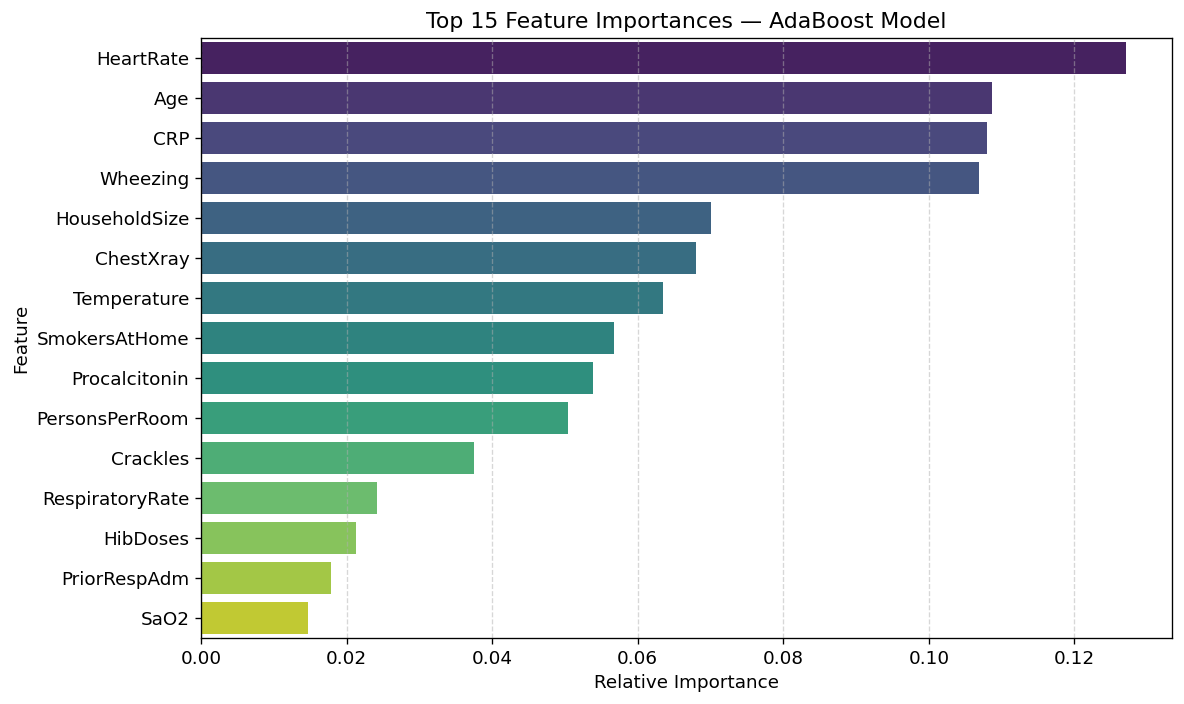

=== TOP 15 ADABOOST FEATURES ===


,Relative Importance
HeartRate,0.127105
Age,0.108697
CRP,0.107995
Wheezing,0.106923
HouseholdSize,0.070088
ChestXray,0.067955
Temperature,0.063480
SmokersAtHome,0.056743
Procalcitonin,0.053826
PersonsPerRoom,0.050459


In [ ]:
# Extract the AdaBoost pipeline and its underlying classifier
adaboost_pipe = fitted["AdaBoost"]
adaboost_clf = adaboost_pipe.named_steps["clf"]

# Extract feature importances
adaboost_importances = pd.Series(
    adaboost_clf.feature_importances_,
    index=selected_features
).sort_values(ascending=False)

# Plot the feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x=adaboost_importances.head(15).values, y=adaboost_importances.head(15).index, palette="viridis")
plt.title("Top 15 Feature Importances — AdaBoost Model")
plt.xlabel("Relative Importance")
plt.ylabel("Feature")
plt.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig("figs/adaboost_feature_importance.png", dpi=150)
plt.show()

# Display the top 15 features in a clean text summary
print("=== TOP 15 ADABOOST FEATURES ===")
display(adaboost_importances.head(15).to_frame(name="Relative Importance"))

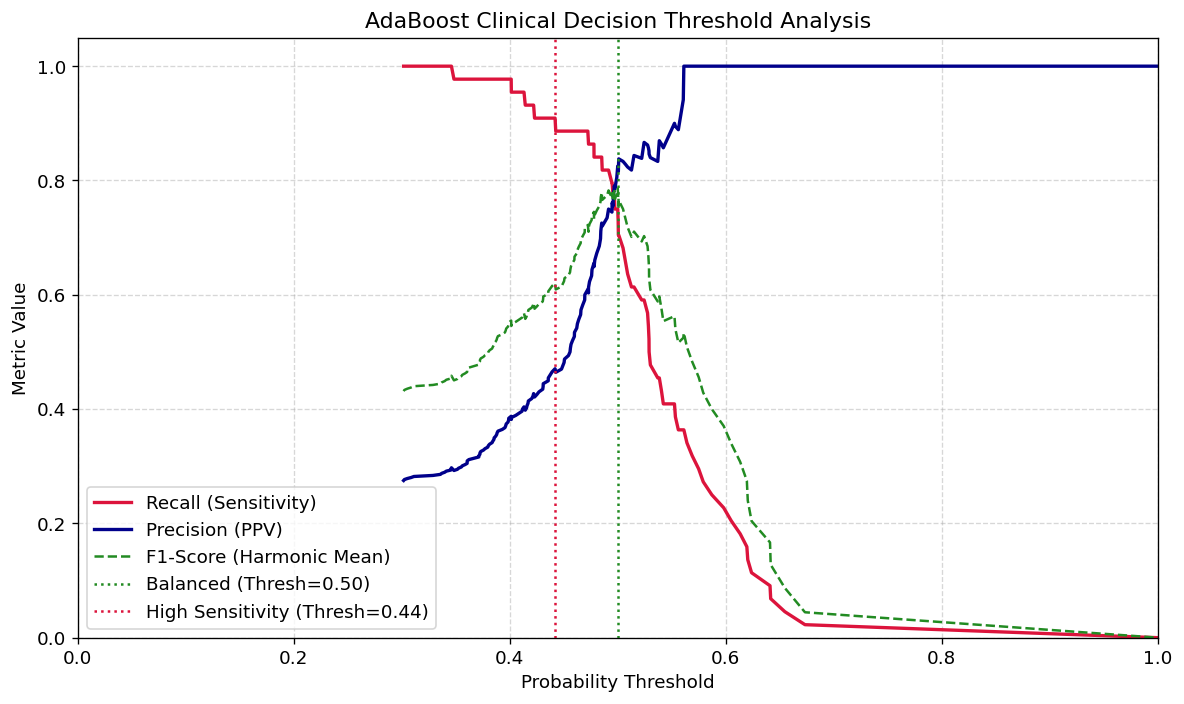

,Clinical Strategy,Threshold,Recall (Sensitivity),Precision (PPV),F1-Score
0,Balanced Diagnostic Profile (Max F1),0.500027,75.0%,82.5%,0.7857
1,Aggressive Screening Mode (Priority: Catch All...,0.441988,90.9%,47.1%,0.6202
2,Confirmatory Mode (Priority: Avoid False Posit...,0.552554,40.9%,90.0%,0.5625


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import precision_recall_curve

# Get predicted probabilities of pneumonia for the test set from AdaBoost
y_prob_adaboost = fitted["AdaBoost"].predict_proba(X_test)[:, 1]

# Calculate precision, recall, and thresholds
precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob_adaboost)

# Create a DataFrame to analyze clinical metrics at various thresholds
threshold_df = pd.DataFrame({
    "Threshold": np.append(thresholds, 1.0),
    "Precision (PPV)": precisions,
    "Recall (Sensitivity)": recalls
})

# Compute F1-score for each threshold
threshold_df["F1-Score"] = 2 * (threshold_df["Precision (PPV)"] * threshold_df["Recall (Sensitivity)"]) / (threshold_df["Precision (PPV)"] + threshold_df["Recall (Sensitivity)"] + 1e-10)

# Let's highlight some clinical scenarios:
# 1. Balanced (Maximize F1)
idx_f1 = threshold_df["F1-Score"].idxmax()

# 2. High Sensitivity / Screening (Recall >= 90%)
idx_sens = threshold_df[threshold_df["Recall (Sensitivity)"] >= 0.90].index[-1]

# 3. High Precision / Confirmatory (Precision >= 90%)
idx_prec = threshold_df[threshold_df["Precision (PPV)"] >= 0.90].index[0] if len(threshold_df[threshold_df["Precision (PPV)"] >= 0.90]) > 0 else idx_f1

# Plot the Recall vs Precision curves across thresholds
plt.figure(figsize=(10, 6))
plt.plot(threshold_df["Threshold"], threshold_df["Recall (Sensitivity)"], label="Recall (Sensitivity)", color="crimson", linewidth=2)
plt.plot(threshold_df["Threshold"], threshold_df["Precision (PPV)"], label="Precision (PPV)", color="darkblue", linewidth=2)
plt.plot(threshold_df["Threshold"], threshold_df["F1-Score"], label="F1-Score (Harmonic Mean)", color="forestgreen", linestyle="--", linewidth=1.5)

# Highlight key threshold choices
plt.axvline(threshold_df.loc[idx_f1, "Threshold"], color="forestgreen", linestyle=":", label=f"Balanced (Thresh={threshold_df.loc[idx_f1, 'Threshold']:.2f})")
plt.axvline(threshold_df.loc[idx_sens, "Threshold"], color="crimson", linestyle=":", label=f"High Sensitivity (Thresh={threshold_df.loc[idx_sens, 'Threshold']:.2f})")

plt.title("AdaBoost Clinical Decision Threshold Analysis")
plt.xlabel("Probability Threshold")
plt.ylabel("Metric Value")
plt.legend(loc="lower left")
plt.grid(True, linestyle="--", alpha=0.5)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])

plt.tight_layout()
plt.savefig("figs/clinical_threshold_analysis.png", dpi=150)
plt.show()

# Display Scenarios Table
scenarios = pd.DataFrame([
    {
        "Clinical Strategy": "Balanced Diagnostic Profile (Max F1)",
        "Threshold": threshold_df.loc[idx_f1, "Threshold"],
        "Recall (Sensitivity)": f"{threshold_df.loc[idx_f1, 'Recall (Sensitivity)']:.1%}",
        "Precision (PPV)": f"{threshold_df.loc[idx_f1, 'Precision (PPV)']:.1%}",
        "F1-Score": f"{threshold_df.loc[idx_f1, 'F1-Score']:.4f}"
    },
    {
        "Clinical Strategy": "Aggressive Screening Mode (Priority: Catch All Cases)",
        "Threshold": threshold_df.loc[idx_sens, "Threshold"],
        "Recall (Sensitivity)": f"{threshold_df.loc[idx_sens, 'Recall (Sensitivity)']:.1%}",
        "Precision (PPV)": f"{threshold_df.loc[idx_sens, 'Precision (PPV)']:.1%}",
        "F1-Score": f"{threshold_df.loc[idx_sens, 'F1-Score']:.4f}"
    },
    {
        "Clinical Strategy": "Confirmatory Mode (Priority: Avoid False Positives)",
        "Threshold": threshold_df.loc[idx_prec, "Threshold"],
        "Recall (Sensitivity)": f"{threshold_df.loc[idx_prec, 'Recall (Sensitivity)']:.1%}",
        "Precision (PPV)": f"{threshold_df.loc[idx_prec, 'Precision (PPV)']:.1%}",
        "F1-Score": f"{threshold_df.loc[idx_prec, 'F1-Score']:.4f}"
    }
])

display(scenarios)

=== COMPREHENSIVE TEST SET MODEL COMPARISON ===


,Model,Test Accuracy,Test ROC-AUC,Test F1-Score,Recall (Sensitivity),Precision (PPV)
0,Random Forest,85.62%,0.9060,0.7294,70.45%,75.61%
1,AdaBoost,88.75%,0.9016,0.7857,75.00%,82.50%
2,Logistic Regression,85.62%,0.8995,0.7473,77.27%,72.34%
3,Decision Tree,81.25%,0.8816,0.6809,72.73%,64.00%
4,SVM (RBF),81.88%,0.8760,0.6742,68.18%,66.67%
5,XGBoost,84.38%,0.8660,0.7059,68.18%,73.17%
6,Gradient Boosting,83.12%,0.8621,0.6966,70.45%,68.89%
7,LightGBM,83.75%,0.8572,0.6905,65.91%,72.50%
8,"MLP (100,50)",85.62%,0.8474,0.7229,68.18%,76.92%
9,KNN (k=7),75.62%,0.8330,0.6422,79.55%,53.85%


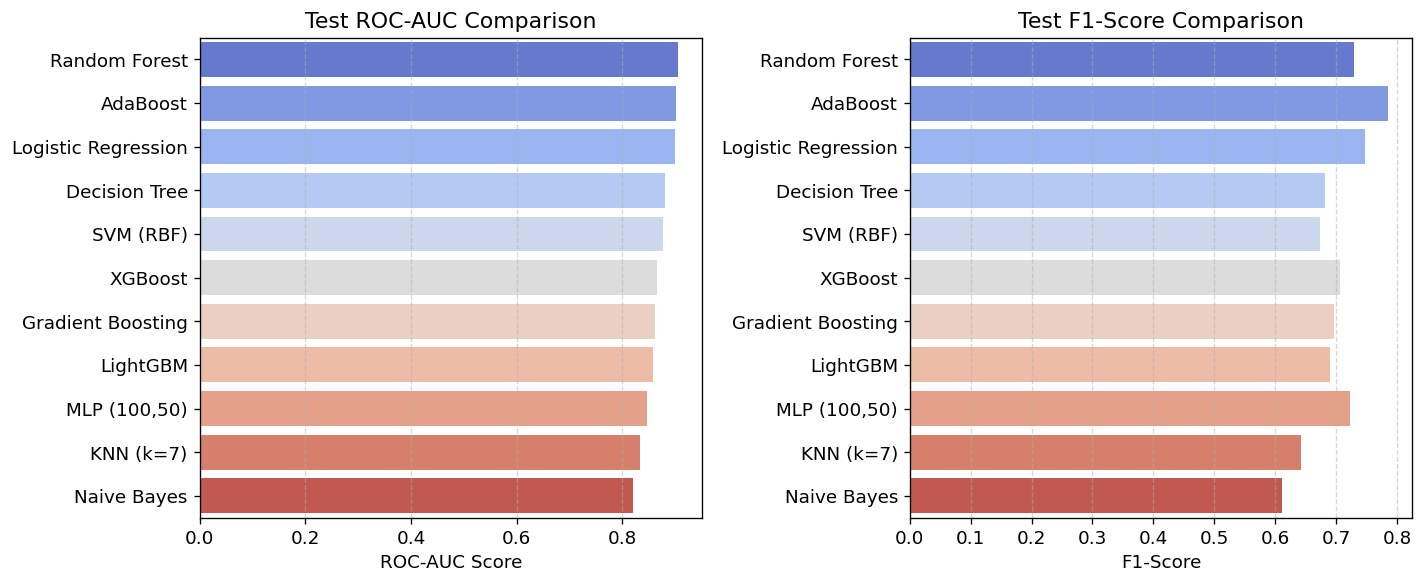

In [ ]:
# Format and compare AdaBoost against all other models on the test set
test_comparison_df = results_df[[
    "Model", "Test Acc", "Test AUC", "Test F1", "Test Recall", "Test Precision"
]].copy()

# Rename columns for clinical clarity
test_comparison_df.columns = [
    "Model", "Test Accuracy", "Test ROC-AUC", "Test F1-Score", "Recall (Sensitivity)", "Precision (PPV)"
]

# Sort models by Test ROC-AUC
test_comparison_df = test_comparison_df.sort_values(by="Test ROC-AUC", ascending=False).reset_index(drop=True)

# Highlight AdaBoost in the dataframe display using a styled dataframe helper
def highlight_adaboost(row):
    if row["Model"] == "AdaBoost":
        return ['background-color: #e6f3ff; font-weight: bold; border: 1.5px solid #1e88e5'] * len(row)
    return [''] * len(row)

print("=== COMPREHENSIVE TEST SET MODEL COMPARISON ===")
display(test_comparison_df.style.apply(highlight_adaboost, axis=1).format({
    "Test Accuracy": "{:.2%}",
    "Test ROC-AUC": "{:.4f}",
    "Test F1-Score": "{:.4f}",
    "Recall (Sensitivity)": "{:.2%}",
    "Precision (PPV)": "{:.2%}"
}))

# Visual comparison of Top models across F1 and ROC-AUC
plt.figure(figsize=(12, 5))

# ROC-AUC comparison
plt.subplot(1, 2, 1)
sns.barplot(data=test_comparison_df, x="Test ROC-AUC", y="Model", palette="coolwarm")
plt.title("Test ROC-AUC Comparison")
plt.xlabel("ROC-AUC Score")
plt.ylabel("")
plt.grid(axis='x', linestyle='--', alpha=0.5)

# F1-Score comparison
plt.subplot(1, 2, 2)
sns.barplot(data=test_comparison_df, x="Test F1-Score", y="Model", palette="coolwarm")
plt.title("Test F1-Score Comparison")
plt.xlabel("F1-Score")
plt.ylabel("")
plt.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig("figs/adaboost_vs_others_comparison.png", dpi=150)
plt.show()

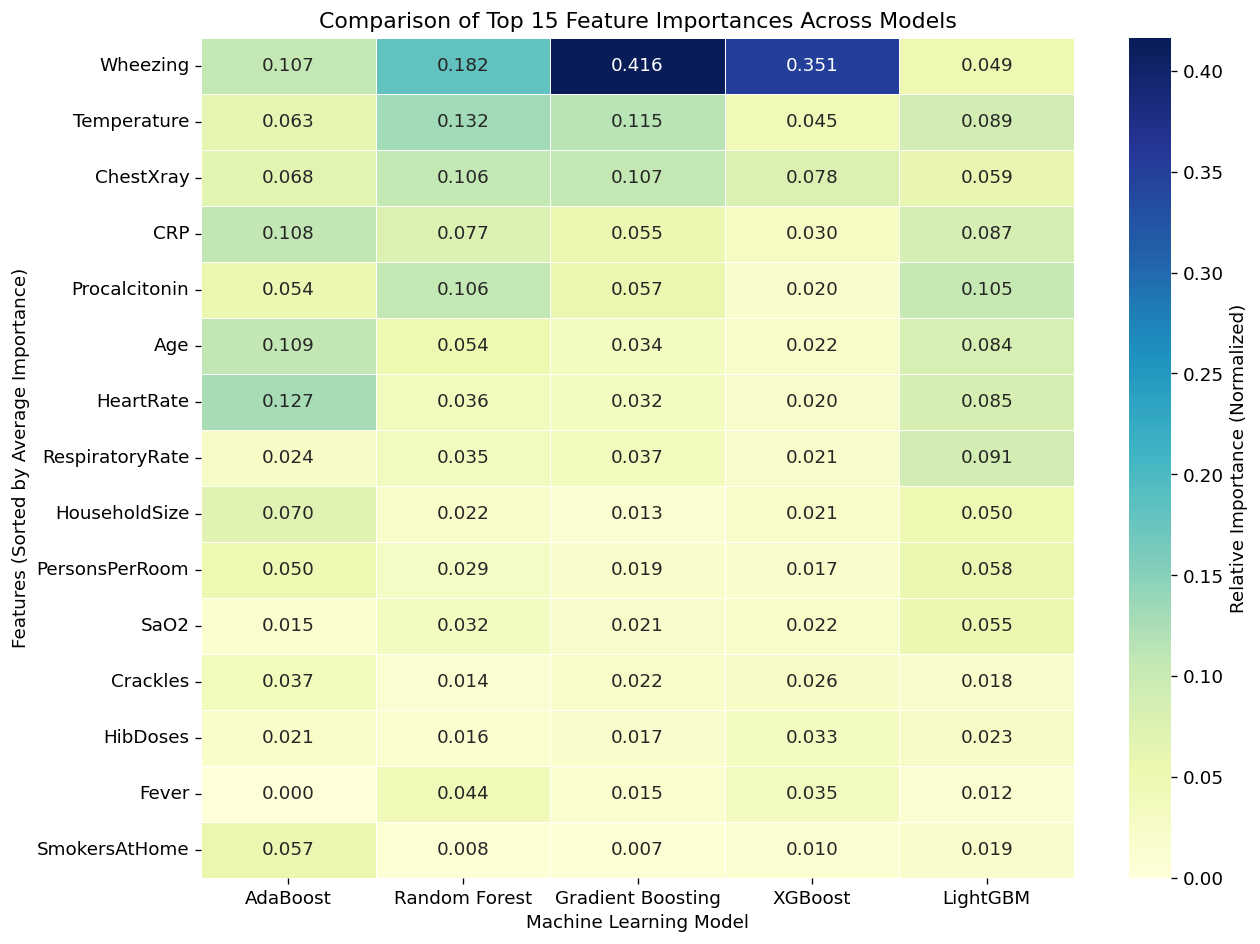

=== TOP SHARED PREDICTORS (AVERAGE IMPORTANCE) ===


,Average
Wheezing,0.221027
Temperature,0.088859
ChestXray,0.083440
CRP,0.071335
Procalcitonin,0.068277
Age,0.060455
HeartRate,0.059977
RespiratoryRate,0.041563
HouseholdSize,0.035238
PersonsPerRoom,0.034669


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Dictionary to hold the feature importances
all_importances = {}

# Models that natively compute feature importances
importance_models = ["AdaBoost", "Random Forest", "Gradient Boosting", "XGBoost", "LightGBM"]

for name in importance_models:
    if name in fitted:
        clf_step = fitted[name].named_steps["clf"]
        if hasattr(clf_step, "feature_importances_"):
            # Normalize importances so they sum to 1 for fair comparison
            raw_imp = clf_step.feature_importances_
            norm_imp = raw_imp / np.sum(raw_imp)
            all_importances[name] = pd.Series(norm_imp, index=selected_features)

# Create a consolidated DataFrame
importance_df = pd.DataFrame(all_importances)

# Sort by the average importance across all models to show key features first
importance_df["Average"] = importance_df.mean(axis=1)
importance_df = importance_df.sort_values(by="Average", ascending=False)
importance_df_to_plot = importance_df.drop(columns=["Average"]).head(15)

# Plot the comparative heatmap
plt.figure(figsize=(11, 8))
sns.heatmap(
    importance_df_to_plot,
    annot=True,
    cmap="YlGnBu",
    fmt=".3f",
    cbar_kws={'label': 'Relative Importance (Normalized)'},
    linewidths=0.5
)

plt.title("Comparison of Top 15 Feature Importances Across Models")
plt.ylabel("Features (Sorted by Average Importance)")
plt.xlabel("Machine Learning Model")
plt.tight_layout()
plt.savefig("figs/comparative_feature_importance.png", dpi=150)
plt.show()

# Print summary of findings
print("=== TOP SHARED PREDICTORS (AVERAGE IMPORTANCE) ===")
display(importance_df[["Average"]].head(10))